### Naive Bayes- bayes theorem and conditional probability

import libraries


In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

### load file, separate features and target, display head

In [2]:
df = pd.read_csv("Heart_dataset")

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

display(df.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### train test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Encode categories and train the model

In [4]:
categorical_columns = X.select_dtypes(include=["object", "category"]).columns
numeric_columns = X.select_dtypes(exclude=["object", "category"]).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns),
        ("numeric", "passthrough", numeric_columns)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("naive_bayes", GaussianNB())
])

model.fit(X_train, y_train)
print("Naive Bayes model trained.")

Naive Bayes model trained.


C:\Users\Nandini\AppData\Local\Temp\ipykernel_30676\992579523.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object", "category"]).columns


Naive Bayes uses probability to estimate which class is most likely given the input features. GaussianNB is a common version for numerical data; it assumes each numerical feature follows a roughly bell-shaped distribution within each class.

### Predict and evaluate

Accuracy: 0.886

Confusion matrix:
[[71 11]
 [10 92]]

Classification report:
                  precision    recall  f1-score   support

No heart disease       0.88      0.87      0.87        82
   Heart disease       0.89      0.90      0.90       102

        accuracy                           0.89       184
       macro avg       0.88      0.88      0.88       184
    weighted avg       0.89      0.89      0.89       184



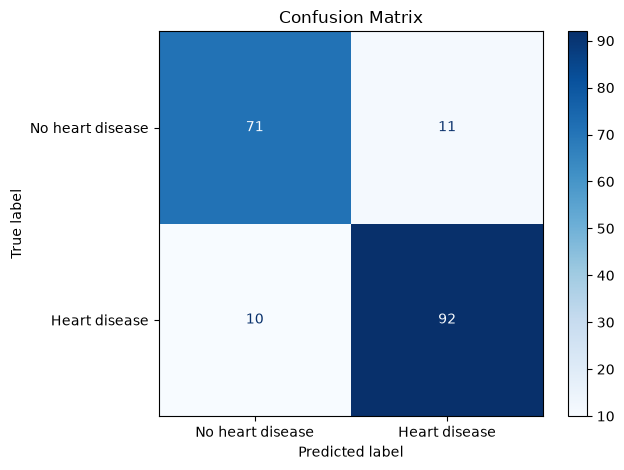

In [7]:
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["No heart disease", "Heart disease"]
))

ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, predictions),
        display_labels=["No heart disease", "Heart disease"],
    ).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix")
plt.tight_layout()
plt.show()
